In [3]:
pip install qiskit qiskit-nature qiskit-algorithms pyscf scipy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 12.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.4/23.4 MB 14.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 11.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit-nature]0m [qiskit-nature]
Note: you may need to restart the kernel to use updated packages.


In [6]:
#make the modelcule
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.units import DistanceUnit

R = 0.8
driver = PySCFDriver(
    atom = f"He 0 0 0; H 0 0 {R}",
    unit = DistanceUnit.ANGSTROM,
    charge = 1,
    spin = 0,
    basis = "sto3g"
)
problem = driver.run()
print("n spatial orbitals:", problem.num_spatial_orbitals)
print("n electrons:", problem.num_particles)

n spatial orbitals: 2
n electrons: (1, 1)


In [12]:
from qiskit_nature.second_q.mappers import JordanWignerMapper

mapper = JordanWignerMapper()
fermionic_hamiltonian = (problem.hamiltonian.second_q_op())
qubit_hamiltonian = mapper.map(fermionic_hamiltonian)
print(qubit_hamiltonian)
print("number of qbits:", qubit_hamiltonian.num_qubits)

SparsePauliOp(['IIII', 'IIIZ', 'IIYY', 'IIXX', 'IIZI', 'IZII', 'YYII', 'XXII', 'ZIII', 'IIZZ', 'IZIZ', 'YYIZ', 'XXIZ', 'ZIIZ', 'IZYY', 'IZXX', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'ZIYY', 'ZIXX', 'IZZI', 'YYZI', 'XXZI', 'ZIZI', 'ZZII'],
              coeffs=[-2.90213083+0.j,  0.75284681+0.j,  0.05363257+0.j,  0.05363257+0.j,
  0.19701607+0.j,  0.75284681+0.j,  0.05363257+0.j,  0.05363257+0.j,
  0.19701607+0.j,  0.12689447+0.j,  0.23567567+0.j,  0.04337626+0.j,
  0.04337626+0.j,  0.1625523 +0.j,  0.04337626+0.j,  0.04337626+0.j,
  0.03565783+0.j,  0.03565783+0.j,  0.03565783+0.j,  0.03565783+0.j,
 -0.0102554 +0.j, -0.0102554 +0.j,  0.1625523 +0.j, -0.0102554 +0.j,
 -0.0102554 +0.j,  0.18783587+0.j,  0.12689447+0.j])
number of qbits: 4


In [17]:
from qiskit_nature.second_q.circuit.library import (
    HartreeFock,
    UCCSD
)
initial_state = HartreeFock(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper
)
ansatz = UCCSD(
    num_spatial_orbitals=problem.num_spatial_orbitals,
    num_particles=problem.num_particles,
    qubit_mapper=mapper,
    initial_state=initial_state
)
print("Number of parameters:",
      ansatz.num_parameters)

Number of parameters: 3


In [18]:
print(ansatz.excitation_list)

[((0,), (1,)), ((2,), (3,)), ((0, 2), (1, 3))]


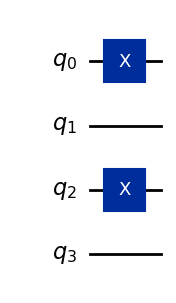

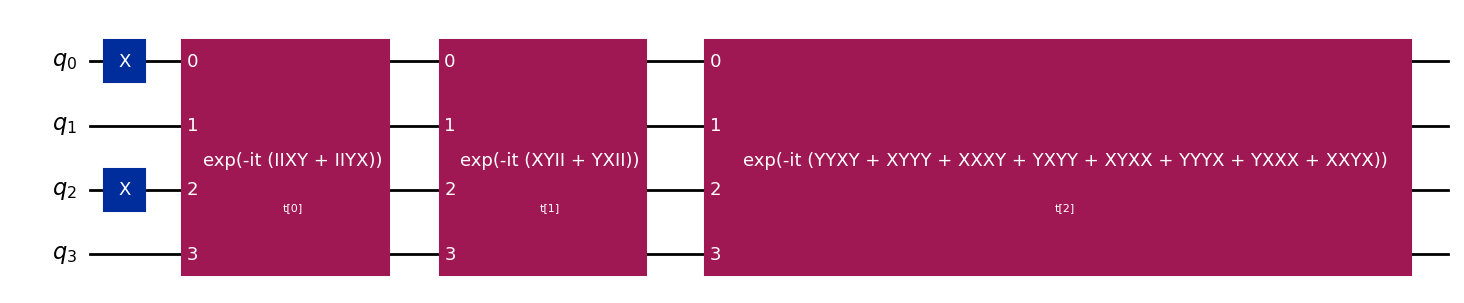

In [20]:
display(initial_state.draw("mpl"))
display(ansatz.decompose().draw("mpl"))

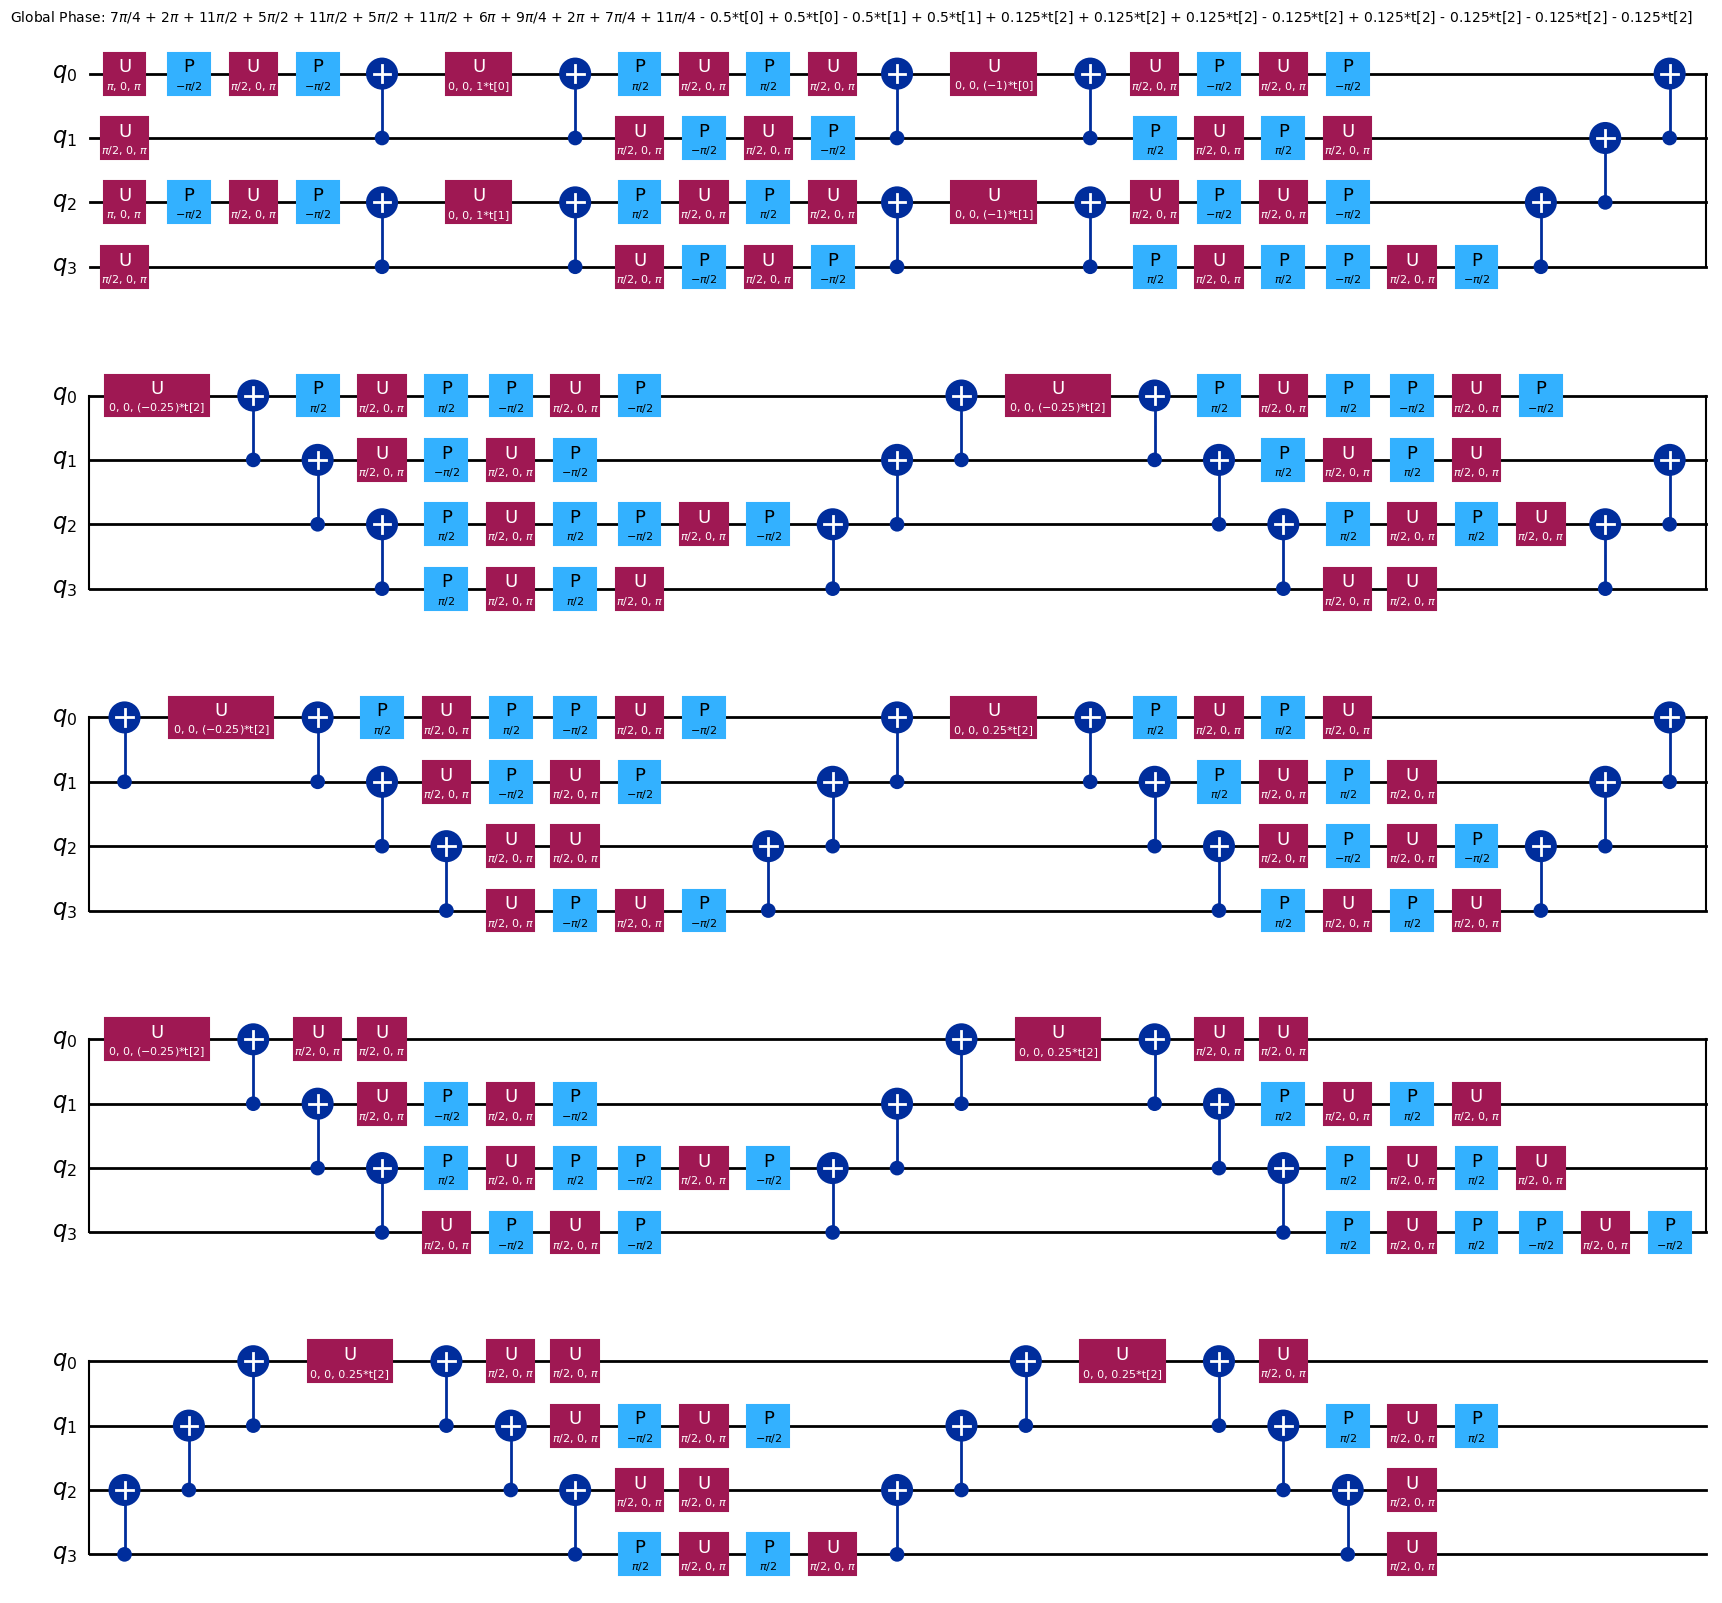

In [22]:
display(ansatz.decompose(reps=4).draw("mpl"))

In [24]:
import numpy as np

H_matrix = qubit_hamiltonian.to_matrix()

print(np.round(H_matrix.real, 3))
print("Matrix shape:", H_matrix.shape)

[[ 0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.    -2.556  0.174  0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.174 -1.349  0.     0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.    -3.397  0.     0.     0.     0.     0.     0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.    -2.556  0.     0.     0.     0.174  0.
   0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.    -4.169  0.     0.     0.     0.
   0.143  0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.    -3.254  0.     0.     0.143
   0.215  0.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.     0.    -4.36   0.     0.
   0.     0.041  0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     0.174  0.     0.     0.    -1.349  0.
   0.     0.    

In [37]:
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP
import numpy as np

estimator = StatevectorEstimator()
optimizer = SLSQP(maxiter=200)
vqe = VQE(
    estimator=estimator,
    ansatz=ansatz,
    optimizer=optimizer,
    initial_point=np.zeros(ansatz.num_parameters)
)
result = vqe.compute_minimum_eigenvalue(qubit_hamiltonian)
electronic_energy = result.eigenvalue.real
nuclear_energy = (problem.hamiltonian.nuclear_repulsion_energy)
total_energy = electronic_energy + nuclear_energy
print("Electronic energy:", electronic_energy)
print("Nuclear repulsion:", nuclear_energy)
print("Total energy:", total_energy)

Electronic energy: -4.178651630162972
Nuclear repulsion: 1.3229430273
Total energy: -2.855708602862972


In [36]:
print("Optimal parameters:", result.optimal_point)
print("Function evaluations:", result.cost_function_evals)
print("Optimal energy:", result.eigenvalue)

Optimal parameters: [-0.01332632 -0.01332641 -0.06663096]
Function evaluations: 14
Optimal energy: -4.178651630162972


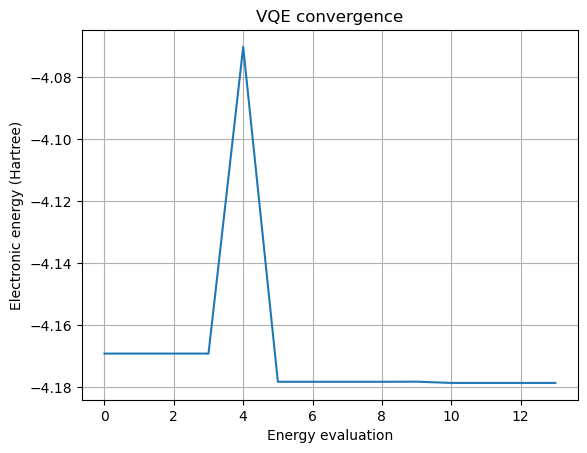

In [40]:
energy_history = []

def callback(eval_count, parameters, energy, metadata):
    energy_history.append(energy)

vqe = VQE(
    estimator=StatevectorEstimator(),
    ansatz=ansatz,
    optimizer=SLSQP(maxiter=200),
    initial_point=np.zeros(ansatz.num_parameters),
    callback=callback
)

result = vqe.compute_minimum_eigenvalue(qubit_hamiltonian)
import matplotlib.pyplot as plt

plt.plot(energy_history)
plt.xlabel("Energy evaluation")
plt.ylabel("Electronic energy (Hartree)")
plt.title("VQE convergence")
plt.grid(True)
plt.show()

In [46]:
from qiskit_nature.second_q.algorithms import (
    GroundStateEigensolver
)
from qiskit_algorithms import NumPyMinimumEigensolver

exact_solver = GroundStateEigensolver(
    mapper,
    NumPyMinimumEigensolver(
        filter_criterion=problem.get_default_filter_criterion()
    )
)
exact_result = exact_solver.solve(problem)

print("Exact total energy:",
      exact_result.total_energies[0].real)
print("VQE total energy:", total_energy)
print("VQE error:", total_energy - exact_result.total_energies[0].real)

Exact total energy: -2.85570862722801
VQE total energy: -2.855708602862972
VQE error: 2.4365037987195137e-08


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
def HeHposenergymin(R,initial_point=None):
    start_time = time.perf_counter()
    driver = PySCFDriver(
        atom = f"He 0 0 0; H 0 0 {R}",
        unit = DistanceUnit.ANGSTROM,
        charge = 1,
        spin = 0,
        basis = "sto3g"
    )
    problem = driver.run()
    mapper = JordanWignerMapper()
    fermionic_hamiltonian = (problem.hamiltonian.second_q_op())
    qubit_hamiltonian = mapper.map(fermionic_hamiltonian)
    initial_state = HartreeFock(
        num_spatial_orbitals=problem.num_spatial_orbitals,
        num_particles=problem.num_particles,
        qubit_mapper=mapper
    )
    ansatz = UCCSD(
        num_spatial_orbitals=problem.num_spatial_orbitals,
        num_particles=problem.num_particles,
        qubit_mapper=mapper,
        initial_state=initial_state
    )
    estimator = StatevectorEstimator()
    optimizer = SLSQP(maxiter=200)
    if initial_point is None:
        initial_point = np.zeros(ansatz.num_parameters)
    vqe = VQE(
        estimator=estimator,
        ansatz=ansatz,
        optimizer=optimizer,
        initial_point=initial_point
    )
    
    result = vqe.compute_minimum_eigenvalue(qubit_hamiltonian)
    electronic_energy = result.eigenvalue.real
    nuclear_energy = (problem.hamiltonian.nuclear_repulsion_energy)
    total_energy = electronic_energy + nuclear_energy
    print("Electronic energy:", electronic_energy)
    print("Nuclear repulsion:", nuclear_energy)
    print("Total energy:", total_energy)
    exact_solver = GroundStateEigensolver(
        mapper,
        NumPyMinimumEigensolver(
            filter_criterion=problem.get_default_filter_criterion()
        )
    )
    exact_result = exact_solver.solve(problem)
    exact_energy = float(exact_result.total_energies[0].real)
    runtime = time.perf_counter() - start_time

    return {
        "R": R,
        "VQE_energy": total_energy,
        "Exact_energy": exact_energy,
        "Error": abs(total_energy - exact_energy),
        "Evaluations": result.cost_function_evals,
        "Runtime": runtime,
        "Optimal_parameters": np.asarray(result.optimal_point)
    }


In [63]:
R_values = np.linspace(0.5, 3.0, 26)

results = []
previous_parameters = None

for i, R in enumerate(R_values):

    data = HeHposenergymin(
        R,
        initial_point=previous_parameters
    )

    results.append(data)

    # Warm-start the next bond length
    previous_parameters = data["Optimal_parameters"]

    print(
        f"{i+1}/{len(R_values)} | "
        f"R = {R:.2f} Å | "
        f"VQE = {data['VQE_energy']:.6f} Ha | "
        f"Error = {data['Error']:.2e} Ha"
    )

df = pd.DataFrame(results)

# Save numerical results
df.drop(columns=["Optimal_parameters"]).to_csv(
    "HeH_PES_results.csv",
    index=False
)

print(df.head())


/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/opt/miniconda3/lib/python3.13/site-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)


1/26 | R = 0.50 Å | VQE = -2.640715 Ha | Error = 7.50e-11 Ha
2/26 | R = 0.60 Å | VQE = -2.770009 Ha | Error = 3.54e-12 Ha
3/26 | R = 0.70 Å | VQE = -2.830483 Ha | Error = 7.39e-12 Ha
4/26 | R = 0.80 Å | VQE = -2.855709 Ha | Error = 3.81e-11 Ha
5/26 | R = 0.90 Å | VQE = -2.862618 Ha | Error = 7.38e-12 Ha
6/26 | R = 1.00 Å | VQE = -2.860205 Ha | Error = 1.24e-07 Ha
7/26 | R = 1.10 Å | VQE = -2.853516 Ha | Error = 6.95e-08 Ha
8/26 | R = 1.20 Å | VQE = -2.845425 Ha | Error = 1.05e-07 Ha
9/26 | R = 1.30 Å | VQE = -2.837497 Ha | Error = 7.71e-08 Ha
10/26 | R = 1.40 Å | VQE = -2.830489 Ha | Error = 1.80e-08 Ha
11/26 | R = 1.50 Å | VQE = -2.824683 Ha | Error = 3.54e-10 Ha
12/26 | R = 1.60 Å | VQE = -2.820091 Ha | Error = 1.53e-08 Ha
13/26 | R = 1.70 Å | VQE = -2.816590 Ha | Error = 3.06e-08 Ha
14/26 | R = 1.80 Å | VQE = -2.813996 Ha | Error = 3.20e-08 Ha
15/26 | R = 1.90 Å | VQE = -2.812117 Ha | Error = 2.38e-08 Ha
16/26 | R = 2.00 Å | VQE = -2.810780 Ha | Error = 1.41e-08 Ha
17/26 | R = 2.10 

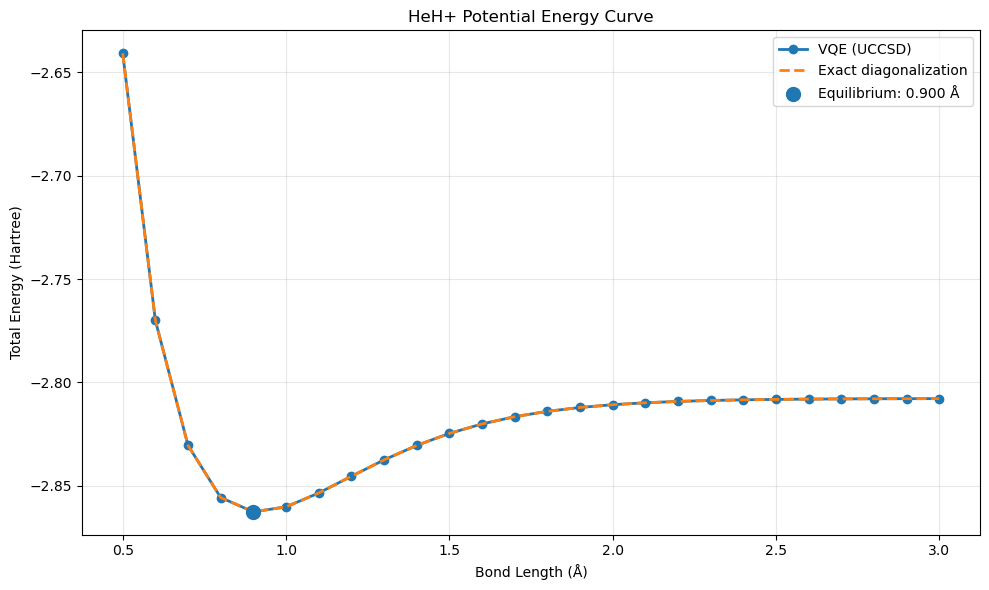

Equilibrium bond length: 0.9000 Å
Minimum energy: -2.86261758 Hartree


In [64]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["R"],
    df["VQE_energy"],
    "o-",
    label="VQE (UCCSD)",
    linewidth=2
)

plt.plot(
    df["R"],
    df["Exact_energy"],
    "--",
    label="Exact diagonalization",
    linewidth=2
)

minimum_index = df["VQE_energy"].idxmin()

R_eq = df.loc[minimum_index, "R"]
E_min = df.loc[minimum_index, "VQE_energy"]

plt.scatter(
    R_eq, E_min,
    s=100,
    zorder=5,
    label=f"Equilibrium: {R_eq:.3f} Å"
)

plt.xlabel("Bond Length (Å)")
plt.ylabel("Total Energy (Hartree)")
plt.title("HeH+ Potential Energy Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("HeH_PES.png", dpi=300)
plt.show()

print(f"Equilibrium bond length: {R_eq:.4f} Å")
print(f"Minimum energy: {E_min:.8f} Hartree")
